In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_cleaned.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [19]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (8807, 12)

Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data Types:
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


In [20]:
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64

## Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution and frequency.

In [21]:
print(df['type'].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


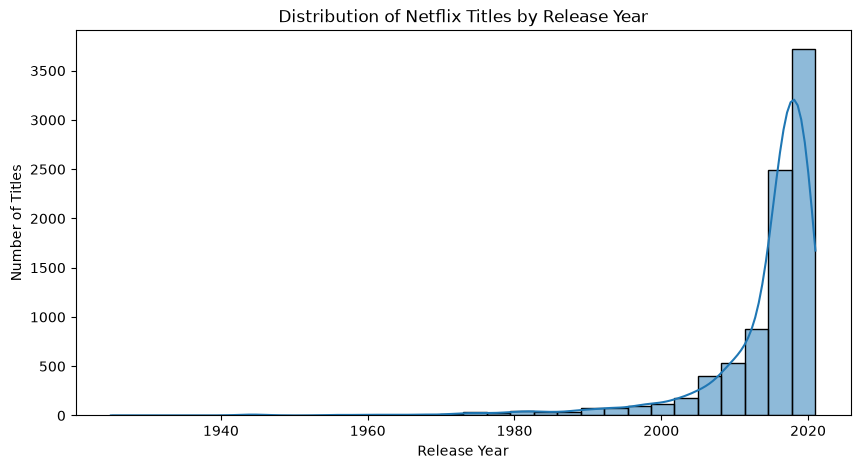

In [22]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='release_year',
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

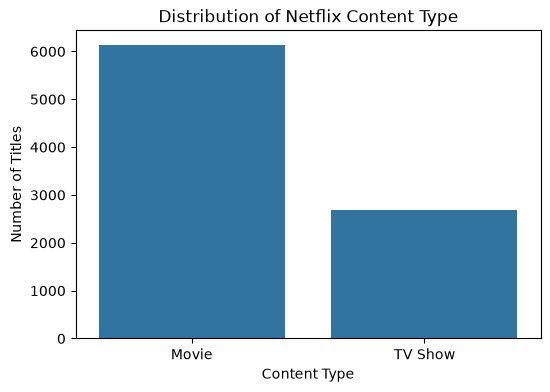

In [23]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='type')

plt.title("Distribution of Netflix Content Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.show()

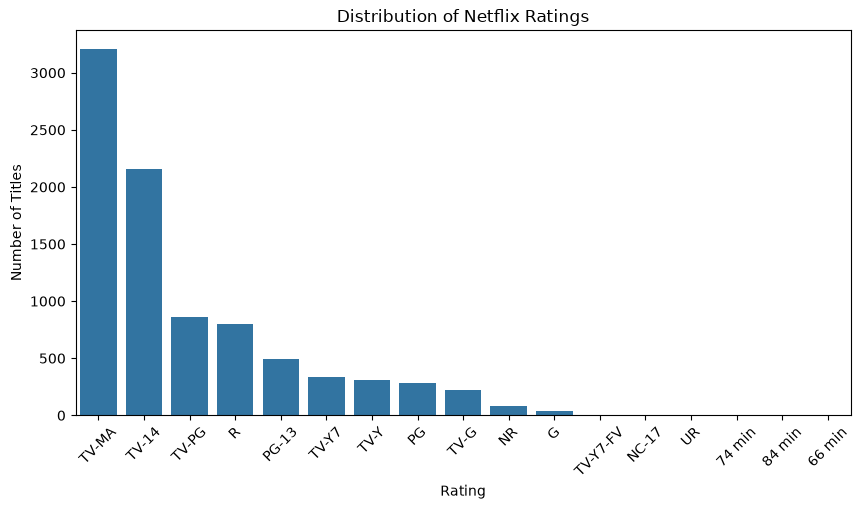

In [24]:
rating_counts = df['rating'].value_counts()

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='rating',
    order=rating_counts.index
)

plt.title("Distribution of Netflix Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

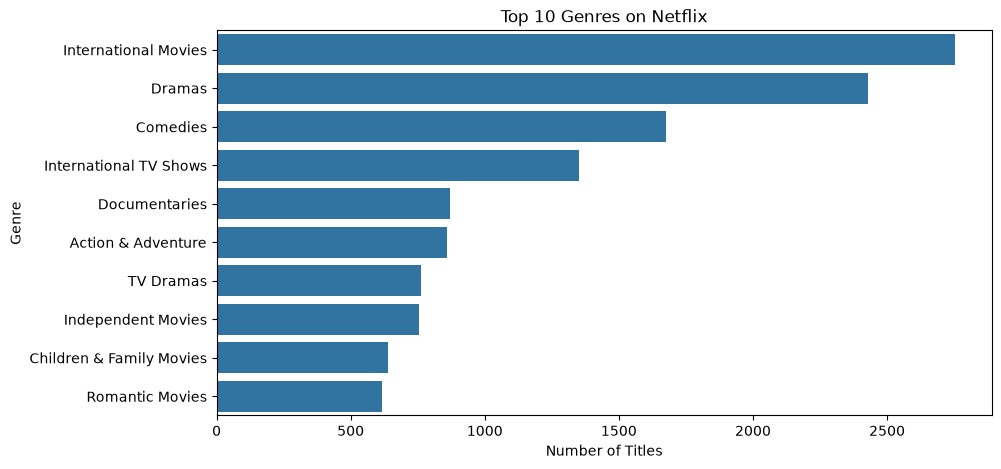

In [25]:
genres = df['listed_in'].dropna().str.split(', ').explode()
genre_counts = genres.value_counts().head(10)

plt.figure(figsize=(10,5))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

## Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

### Movie Duration vs Release Year

For Movies, the duration column is converted from text into numerical minutes so that its relationship with release year can be analyzed.

In [26]:
movies = df[df['type'] == 'Movie'].copy()

movies['duration_min'] = pd.to_numeric(
    movies['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

movies[['release_year', 'duration', 'duration_min']].head()

,release_year,duration,duration_min
0,2020,90 min,90.0
6,2021,91 min,91.0
7,1993,125 min,125.0
9,2021,104 min,104.0
12,2021,127 min,127.0


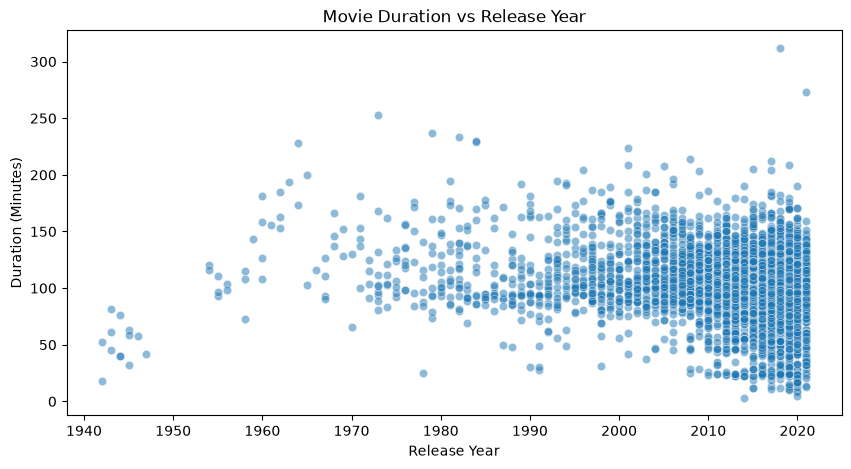

In [27]:
plt.figure(figsize=(10,5))

sns.scatterplot(
    data=movies,
    x='release_year',
    y='duration_min',
    alpha=0.5
)

plt.title("Movie Duration vs Release Year")
plt.xlabel("Release Year")
plt.ylabel("Duration (Minutes)")

plt.show()

### Observation

The scatter plot shows the relationship between the release year of movies and their duration.

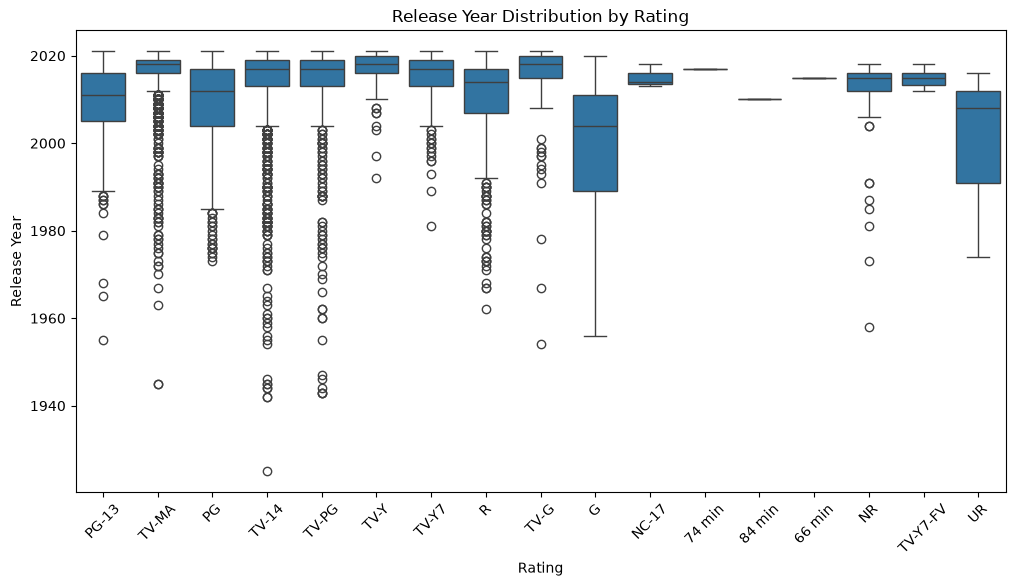

In [28]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x='rating',
    y='release_year'
)

plt.title("Release Year Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Release Year")
plt.xticks(rotation=45)

plt.show()

### Observation

The box plot compares the distribution of release years across different content ratings.

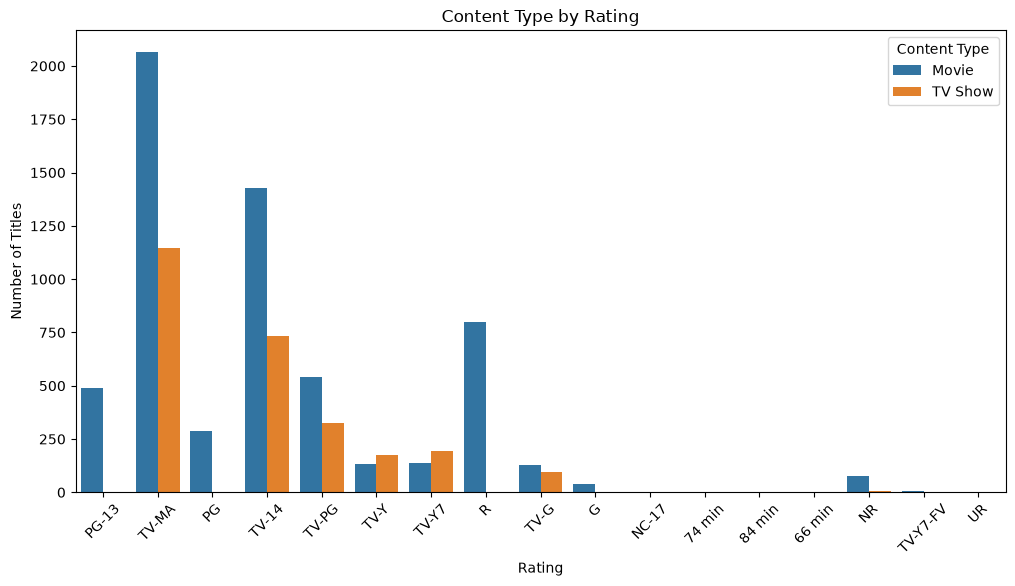

In [29]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='rating',
    hue='type'
)

plt.title("Content Type by Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")

plt.show()

### Observation

The plot compares how different content ratings are distributed between Movies and TV Shows.

In [30]:
correlation = movies['release_year'].corr(movies['duration_min'])

print("Correlation between Release Year and Movie Duration:", correlation)

Correlation between Release Year and Movie Duration: -0.20628474681965622


### Observation

The correlation value indicates the strength and direction of the relationship between movie release year and duration.

## Descriptive Statistics

Descriptive statistics are used to summarize the numerical characteristics of the Netflix dataset.

The main measures considered are:
- Mean
- Median
- Standard Deviation
- Minimum
- Maximum
- Skewness
- Kurtosis

These measures help us understand the central tendency, spread, and distribution shape of the numerical variables.

In [31]:
print("Release Year Statistics")
print("-----------------------")
print("Mean:", df['release_year'].mean())
print("Median:", df['release_year'].median())
print("Standard Deviation:", df['release_year'].std())
print("Minimum:", df['release_year'].min())
print("Maximum:", df['release_year'].max())
print("Skewness:", df['release_year'].skew())
print("Kurtosis:", df['release_year'].kurt())

Release Year Statistics
-----------------------
Mean: 2014.1801975701146
Median: 2017.0
Standard Deviation: 8.819312130833966
Minimum: 1925
Maximum: 2021
Skewness: -3.4465650403316013
Kurtosis: 16.232225648417078


In [32]:
print("Movie Duration Statistics")
print("-------------------------")
print("Mean:", movies['duration_min'].mean())
print("Median:", movies['duration_min'].median())
print("Standard Deviation:", movies['duration_min'].std())
print("Minimum:", movies['duration_min'].min())
print("Maximum:", movies['duration_min'].max())

Movie Duration Statistics
-------------------------
Mean: 99.57718668407311
Median: 98.0
Standard Deviation: 28.290593447417397
Minimum: 3.0
Maximum: 312.0


### Interpretation

- **Mean** represents the average release year of the titles.
- **Median** represents the middle release year when all titles are ordered.
- **Standard deviation** indicates how much the release years vary around the mean.
- **Minimum and maximum** show the range of release years present in the dataset.

## Skewness

Skewness measures the asymmetry of a numerical distribution.

- Skewness close to 0 indicates a relatively symmetric distribution.
- Positive skewness indicates a longer tail toward higher values.
- Negative skewness indicates a longer tail toward lower values.

In [33]:
skewness = df['release_year'].skew()

print("Skewness of Release Year:", skewness)

Skewness of Release Year: -3.4465650403316013


In [36]:
if skewness > 0:
    print("The distribution is positively skewed.")
elif skewness < 0:
    print("The distribution is negatively skewed.")
else:
    print("The distribution is approximately symmetric.")

The distribution is negatively skewed.


## Kurtosis

Kurtosis describes the shape of a distribution, particularly the degree to which it has heavy or light tails compared with a normal distribution.

Pandas returns **excess kurtosis** by default.

- Kurtosis close to 0 indicates a distribution similar to the normal distribution in terms of tail heaviness.
- Positive kurtosis indicates relatively heavier tails.
- Negative kurtosis indicates relatively lighter tails.

In [34]:
kurtosis = df['release_year'].kurt()

print("Kurtosis of Release Year:", kurtosis)

Kurtosis of Release Year: 16.232225648417078


In [35]:
if kurtosis > 0:
    print("The distribution has relatively heavier tails.")
elif kurtosis < 0:
    print("The distribution has relatively lighter tails.")
else:
    print("The distribution has approximately normal tail behaviour.")

The distribution has relatively heavier tails.


## EDA Summary

The Exploratory Data Analysis provided an understanding of the Netflix dataset through both visual and statistical methods.

Univariate analysis was used to study individual variables, while bivariate analysis was used to examine relationships between variables.

Descriptive statistics such as mean, median and standard deviation were used to understand the central tendency and dispersion of the release year. Skewness and kurtosis were calculated to understand the shape and distribution characteristics of the numerical data.

These findings provide a foundation for further data preprocessing, feature engineering and advanced analysis.